# Where does the skill extractor fail? Error analysis on SkillSpan

Model: [`srish327/deberta-v3-skillspan-crf`](https://huggingface.co/srish327/deberta-v3-skillspan-crf). It is DeBERTa-v3 with two BIO heads (SKILL, KNOWLEDGE)
and a learned CRF. Code: [MSR327/skillspan-ner](https://github.com/MSR327/skillspan-ner).

Exact-match span F1 is strict: a skill like *"manage a small team of engineers"* counts as wrong if the model predicts *"manage a small team"*.
This notebook asks **what kind of wrong** each error is. Runs on CPU in ~2 min, or GPU in seconds.

In [1]:
try:
    import skillex  # noqa: F401
except ImportError:  # Kaggle / Colab
    %pip install -q "skillex @ git+https://github.com/MSR327/skillspan-ner.git" datasets
import json
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForTokenClassification, AutoTokenizer

from skillex.crf import load_crfs
from skillex.data import load_skillspan, tokenize_dataset
from skillex.decode import decode_head
from skillex.errors import BOUNDARY, categorize, partial_prf
from skillex.labels import BIO2ID, IGNORE_INDEX, NUM_BIO, TYPES, decode_pair

MODEL = "srish327/deberta-v3-skillspan-crf"
device = "cuda" if torch.cuda.is_available() else "cpu"
pd.set_option("display.precision", 3)

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Predict the whole test set (CRF decoding, one pass)

In [2]:
tok = AutoTokenizer.from_pretrained(MODEL)
model = AutoModelForTokenClassification.from_pretrained(MODEL).to(device).eval()
crfs = load_crfs(MODEL)
test = load_skillspan()["test"]
enc = tokenize_dataset({"test": test}, tok)["test"]


def spans(ids):
    """BIO ids -> set of (start, end) word spans; a stray I starts a span (conlleval)."""
    out, start = set(), None
    for i, t in enumerate(list(ids) + [BIO2ID["O"]]):
        if start is not None and t != BIO2ID["I"]:
            out.add((start, i))
            start = None
        if t == BIO2ID["B"] or (t == BIO2ID["I"] and start is None):
            start = i
    return out


gold = {t: [] for t in TYPES}
pred = {t: [] for t in TYPES}
with torch.inference_mode():
    for i in range(len(enc)):
        x = torch.tensor([enc[i]["input_ids"]], device=device)
        logits = model(input_ids=x).logits[0].cpu().numpy()
        keep = np.array(enc[i]["labels"]) != IGNORE_INDEX  # first subword of each word
        words = logits[keep]
        assert len(words) == len(test[i]["tokens"])
        gold_pairs = [decode_pair(v) for v in test[i]["ner_tags"]]  # (skill_id, knowledge_id) per word
        for h, t in enumerate(TYPES):
            pred[t].append(spans(decode_head(words[:, h * NUM_BIO:(h + 1) * NUM_BIO], "crf", crfs[h])))
            gold[t].append(spans([pair[h] for pair in gold_pairs]))
print({t: (sum(map(len, gold[t])), sum(map(len, pred[t]))) for t in TYPES}, "(gold, predicted) spans")

W1113 15:15:01.544000 90072 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 200/200 [00:00<00:00, 7403.37it/s]


[transformers] DebertaV2ForTokenClassification LOAD REPORT from: srish327/deberta-v3-skillspan-crf
Key                          | Status     |  | 
-----------------------------+------------+--+-
skillex_crf.{0, 1}.raw_start | UNEXPECTED |  | 
skillex_crf.{0, 1}.raw_trans | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Map:   0%|          | 0/4800 [00:00<?, ? examples/s]

Map:  91%|█████████ | 4359/4800 [00:00<00:00, 43415.01 examples/s]

... (4 outputs left out)

Map: 100%|██████████| 3569/3569 [00:00<00:00, 48952.15 examples/s]

Map:   0%|          | 0/3569 [00:00<?, ? examples/s]

Map: 100%|██████████| 3569/3569 [00:00<00:00, 48009.08 examples/s]

{'SKILL': (1091, 1095), 'KNOWLEDGE': (1174, 1224)} (gold, predicted) spans


## 2. Strict vs. lenient F1

*Lenient* means a span counts if it overlaps a gold span of the same type. The gap between the two numbers is the **boundary problem**.

In [3]:
rows = []
for t in TYPES:
    tp = sum(len(g & p) for g, p in zip(gold[t], pred[t]))
    n_p, n_g = sum(map(len, pred[t])), sum(map(len, gold[t]))
    P, R = tp / n_p, tp / n_g
    lenient = partial_prf(gold[t], pred[t])
    rows.append({"type": t, "exact P": P, "exact R": R, "exact F1": 2 * P * R / (P + R),
                 "lenient P": lenient["precision"], "lenient R": lenient["recall"], "lenient F1": lenient["f1"]})
f1 = pd.DataFrame(rows).set_index("type")
f1["gap"] = f1["lenient F1"] - f1["exact F1"]
f1

,exact P,exact R,exact F1,lenient P,lenient R,lenient F1,gap
type,,,,,,,
SKILL,0.536,0.538,0.537,0.795,0.842,0.818,0.281
KNOWLEDGE,0.703,0.733,0.718,0.827,0.883,0.854,0.136


## 3. What kind of errors? Every gold span and every non-exact prediction, categorized

Gold spans (share of all gold spans of that type):


,correct,too_short,too_long,shifted,missed
SKILL,0.538,0.052,0.245,0.007,0.158
KNOWLEDGE,0.733,0.043,0.104,0.003,0.117


Non-exact predictions (share of all predictions of that type):


,too_short,too_long,shifted,wrong_type,spurious
SKILL,0.068,0.185,0.005,0.024,0.181
KNOWLEDGE,0.057,0.065,0.002,0.068,0.105


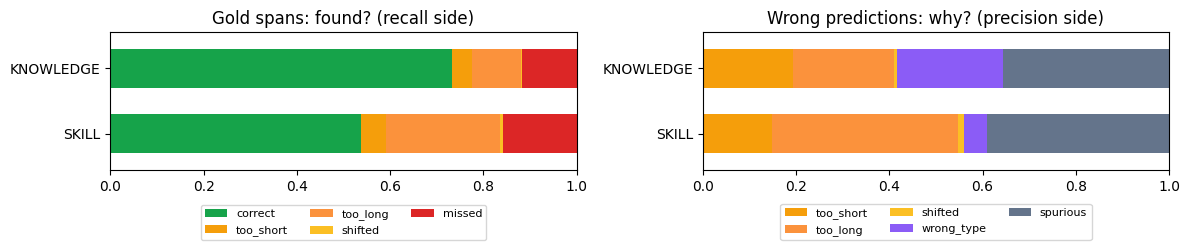

In [4]:
g_tot = {t: Counter() for t in TYPES}
p_tot = {t: Counter() for t in TYPES}
other = {"SKILL": "KNOWLEDGE", "KNOWLEDGE": "SKILL"}
for t in TYPES:
    for G, P, O in zip(gold[t], pred[t], gold[other[t]]):
        g, p = categorize(G, P, O)
        g_tot[t] += g
        p_tot[t] += p

gold_cols = ["correct", *BOUNDARY, "missed"]
pred_cols = [*BOUNDARY, "wrong_type", "spurious"]
gdf = pd.DataFrame({t: g_tot[t] for t in TYPES}).T.reindex(columns=gold_cols, fill_value=0)
pdf = pd.DataFrame({t: p_tot[t] for t in TYPES}).T.reindex(columns=pred_cols, fill_value=0)
print("Gold spans (share of all gold spans of that type):")
display((gdf.T / gdf.sum(1)).T.round(3))
print("Non-exact predictions (share of all predictions of that type):")
display((pdf.T / (pdf.sum(1) + gdf["correct"])).T.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
colors = {"correct": "#16a34a", "too_short": "#f59e0b", "too_long": "#fb923c", "shifted": "#fbbf24",
          "missed": "#dc2626", "wrong_type": "#8b5cf6", "spurious": "#64748b"}
for ax, df, title in [(axes[0], gdf, "Gold spans: found? (recall side)"),
                      (axes[1], pdf, "Wrong predictions: why? (precision side)")]:
    share = (df.T / df.sum(1)).T
    share.plot.barh(stacked=True, ax=ax, color=[colors[c] for c in share.columns], width=0.6)
    ax.set_title(title); ax.set_xlim(0, 1); ax.legend(ncol=3, fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.55))
plt.tight_layout(); plt.show()

## 4. Does span length matter? Exact recall by gold span length

n  exact_recall  overlap_recall
type      len                                   
KNOWLEDGE 1    633         0.804           0.913
          2    371         0.733           0.876
          3     82         0.561           0.817
          4-5   53         0.358           0.679
          6-9   34         0.441           0.882
          10+    1         0.000           1.000
SKILL     1    201         0.448           0.776
          2    188         0.473           0.840
          3    167         0.467           0.790
          4-5  290         0.593           0.869
          6-9  210         0.676           0.914
          10+   35         0.457           0.829

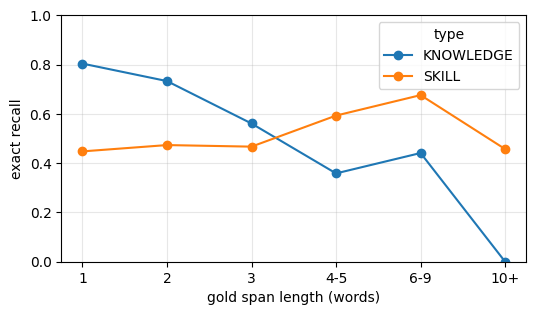

In [5]:
def bucket(n):
    return "1" if n == 1 else "2" if n == 2 else "3" if n == 3 else "4-5" if n <= 5 else "6-9" if n <= 9 else "10+"

order = ["1", "2", "3", "4-5", "6-9", "10+"]
rows = []
for t in TYPES:
    for G, P in zip(gold[t], pred[t]):
        for g in G:
            rows.append({"type": t, "len": bucket(g[1] - g[0]), "exact": g in P,
                         "overlap": any(a < g[1] and g[0] < b for a, b in P)})
L = pd.DataFrame(rows)
by_len = L.groupby(["type", "len"]).agg(n=("exact", "size"), exact_recall=("exact", "mean"),
                                        overlap_recall=("overlap", "mean")).reindex(order, level="len")
display(by_len)
ax = by_len["exact_recall"].unstack(0).reindex(order).plot(marker="o", figsize=(6, 3.2))
ax.set_ylabel("exact recall"); ax.set_xlabel("gold span length (words)"); ax.set_ylim(0, 1); ax.grid(alpha=.3)
plt.show()

## 5. Examples of each error type

In [6]:
rng = np.random.default_rng(0)
toks = test["tokens"]


def show(t, kind, k=4):
    found = []
    for i, (G, P) in enumerate(zip(gold[t], pred[t])):
        for g in G - P:
            hits = [p for p in P if p[0] < g[1] and g[0] < p[1]]
            if kind == "missed" and not hits:
                found.append((i, g, None))
            elif kind != "missed" and hits:
                p = max(hits, key=lambda p: min(g[1], p[1]) - max(g[0], p[0]))
                k_ = "too_short" if g[0] <= p[0] and p[1] <= g[1] else "too_long" if p[0] <= g[0] and g[1] <= p[1] else "shifted"
                if k_ == kind:
                    found.append((i, g, p))
    print(f"--- {t} / {kind} ({len(found)}) ---")
    for j in rng.choice(len(found), size=min(k, len(found)), replace=False):
        i, g, p = found[j]
        print("  gold:", " ".join(toks[i][g[0]:g[1]]))
        if p: print("  pred:", " ".join(toks[i][p[0]:p[1]]))
        print()


for t, kind in [("SKILL", "too_short"), ("SKILL", "too_long"), ("SKILL", "missed"), ("KNOWLEDGE", "missed")]:
    show(t, kind)

--- SKILL / too_short (57) ---
  gold: developing mobile games with a large amount of content delivery
  pred: developing mobile games

  gold: Good at acquiring new skills
  pred: acquiring new skills

  gold: constructive feedback for improvement
  pred: constructive feedback

  gold: see great challenges in being tasked with tactical as well as strategic marketing problems
  pred: being tasked with tactical as well as strategic marketing problems

--- SKILL / too_long (267) ---
  gold: solving business problems
  pred: solving business problems through innovation & engineering practices

  gold: solve biological/mathematical challenges
  pred: analyse and contribute to solve biological/mathematical challenges

  gold: faithful implementation
  pred: eye for aesthetics design and faithful implementation

  gold: proposal development and presentation
  pred: lead generation appointment setting proposal development and presentation

--- SKILL / missed (172) ---
  gold: Fast turnaround 

In [7]:
def spurious(t, k=12):
    c = Counter()
    for i, (G, P, O) in enumerate(zip(gold[t], pred[t], gold[other[t]])):
        for p in P - G:
            if not any(p[0] < g[1] and g[0] < p[1] for g in G | O):
                c[" ".join(toks[i][p[0]:p[1]])] += 1
    return c.most_common(k)

print("Most frequent spurious KNOWLEDGE predictions:", spurious("KNOWLEDGE"))
print()
print("Most frequent spurious SKILL predictions:", spurious("SKILL", 8))

Most frequent spurious KNOWLEDGE predictions: [('modern programming languages', 4), ('Danish', 4), ('DevOps', 3), ('machine learning', 2), ('English', 2), ('ITIL', 2), ('TDD', 2), ('integration testing', 2), ('continuous integration', 2), ('BDD', 2), ('interface', 2), ('Quantitative Research', 1)]

Most frequent spurious SKILL predictions: [('passionate', 2), ('have a broad interface', 2), ('ambitious', 2), ('active', 2), ('enthusiasm', 2), ('shape the key components of the product', 1), ('create commercial opportunities for a new business initiative', 1), ('allowing clients to easily define and compute analytics on a wide variety of financial instruments', 1)]


## 6. Conclusions

1. **The model mostly finds skills. Where it fails is the boundaries.** Skill F1 is 0.537 under exact match but **0.818** when any overlap counts,
   a 28-point gap (knowledge: 14 points). Only 16% of gold skills are missed outright.
2. **Spans run too long far more often than too short.** 24.5% of gold skills are covered by a *longer* prediction, and only 5% by a shorter one.
   The examples show why: when a posting lists coordinated skills (*"lead generation, appointment setting, proposal development and presentation"*),
   annotators tag each item, while the model tags the whole list as one span.
3. **Short skills are the hard ones, not long ones.** Exact recall is ~0.46 for 1 to 3 word skills and 0.68 for 6 to 9 word skills, against the intuition
   that long spans are harder. Short skills get absorbed into longer predicted spans (point 2).
   For knowledge, the opposite holds: single terms (*Python*) have 0.80 exact recall, and 4+ word terms drop below 0.45.
4. **Many "false positives" look like label noise.** The most frequent spurious knowledge predictions (*DevOps, TDD, BDD, ITIL, continuous integration, Danish*)
   are knowledge by any reasonable definition. They just weren't annotated in that sentence. Annotator agreement on SkillSpan is only κ ≈ 0.70 to 0.75,
   so part of the gap to perfect F1 can't be closed.
5. **What to try next:** (a) a split rule for coordinated lists (commas and "and"), aimed at the too-long errors;
   (b) report lenient F1 next to exact F1 for downstream use. A skill search or job-matching system cares whether *"stakeholder management"*
   was found, not whether the span also included *"with senior"*.
